## Test Open SANOS



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.sanos.utils
%aimport quantdata.sanos.open
%aimport quantdata.sanos.fitter

from quantdata.dysanos.simple.aec import load_data
data = load_data(["SPX"]).data['SPX']
print(f"/done; columns {data.keys()}")


00: Importing torch...done; this took 0.00525ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 1.6s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 1.6s.
/done; columns dict_keys(['dates', 'ask_pure_delta', 'ask_pure_dk', 'ask_pure_gamma', 'ask_pure_price', 'ask_pure_theta', 'ask_pure_vega', 'ask_vol', 'bid_pure_delta', 'bid_pure_dk', 'bid_pure_gamma', 'bid_pure_price', 'bid_pure_theta', 'bid_pure_vega', 'bid_vol', 'call_ask', 'call_bid', 'df', 'fw

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/open.py:236: UserWarning: Found the following market data issues: 'pure_strikes[8]' last strike 1.015  must be above the previous expiry's strike 1.015; 'pure_strikes[9]' last strike 1.016  must be above the previous expiry's strike 1.025; 'pure_strikes[10]' last strike 1.015  must be above the previous expiry's strike 1.035; 'pure_strikes[11]' last strike 1.019  must be above the previous expiry's strike 1.046; 'pure_strikes[12]' first strike 0.982  must be below the previous expiry's strike 0.9819; 'pure_strikes[12]' last strike 1.018  must be above the previous expiry's strike 1.056; 'pure_strikes[13]' first strike 0.9819  must be below the previous expiry's strike 0.9721; 'pure_strikes[13]' last strike 1.018  must be above the previous expiry's strike 1.067; 'pure_strikes[14]' first strike 0.9801  must be below the previous expiry's strike 0.9624; 'pure_strikes[14]' last strike 1.018  must be above the previous expiry's 

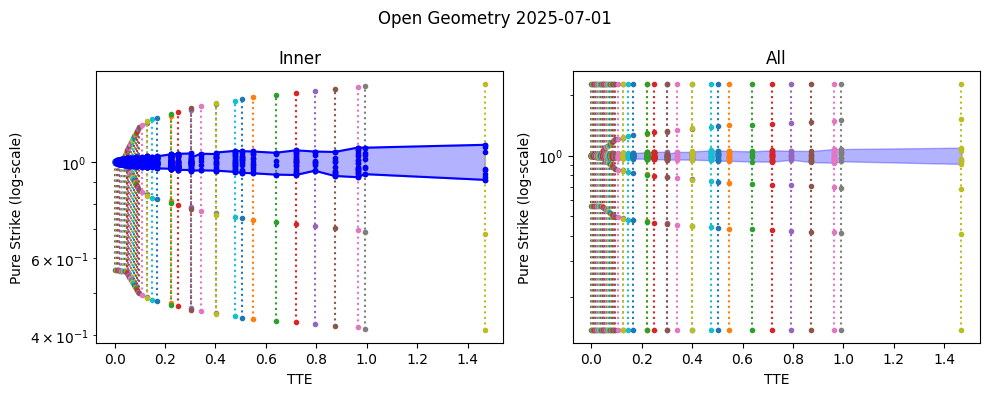

00: Solving for implied DLVs (squared) for 1000 options. Mean half spread is 5.0551e-05... done with relative excess error conditional mean 1.6704e+01, std 2.3891e+01, 95th percentile 7.5016e+01, 99th percentile 9.7702e+01, 99.9th percentile 1.1289e+02 and max 1.1478e+02. This took 0.28s.
00: Computing DLV squared's... done; this tool 1.75ms.


/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/utils.py:429: UserWarning: Found option with expiry 0.003968 (in years) whose strike 0.995 is at or below the second-lowest model strike 0.995 for the next expiry used to compute the model option price. This is likely causing errors. Widen strike range.
/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/utils.py:432: UserWarning: Found option with expiry 0.003968 (in years) whose strike 1.006 is at or above the second-highest model strike 1.005 for the next expiry used to compute the model option price. This is likely causing errors. Widen strike range.
/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/sanos/utils.py:429: UserWarning: Found option with expiry 0.007937 (in years) whose strike 0.9923 is at or below the second-lowest model strike 0.9923 for the next expiry used to compute the model option price. This is likely causing errors. Widen strike range.
/mnt/c/Users/hans/OneDrive/Python3/quant_data/qua

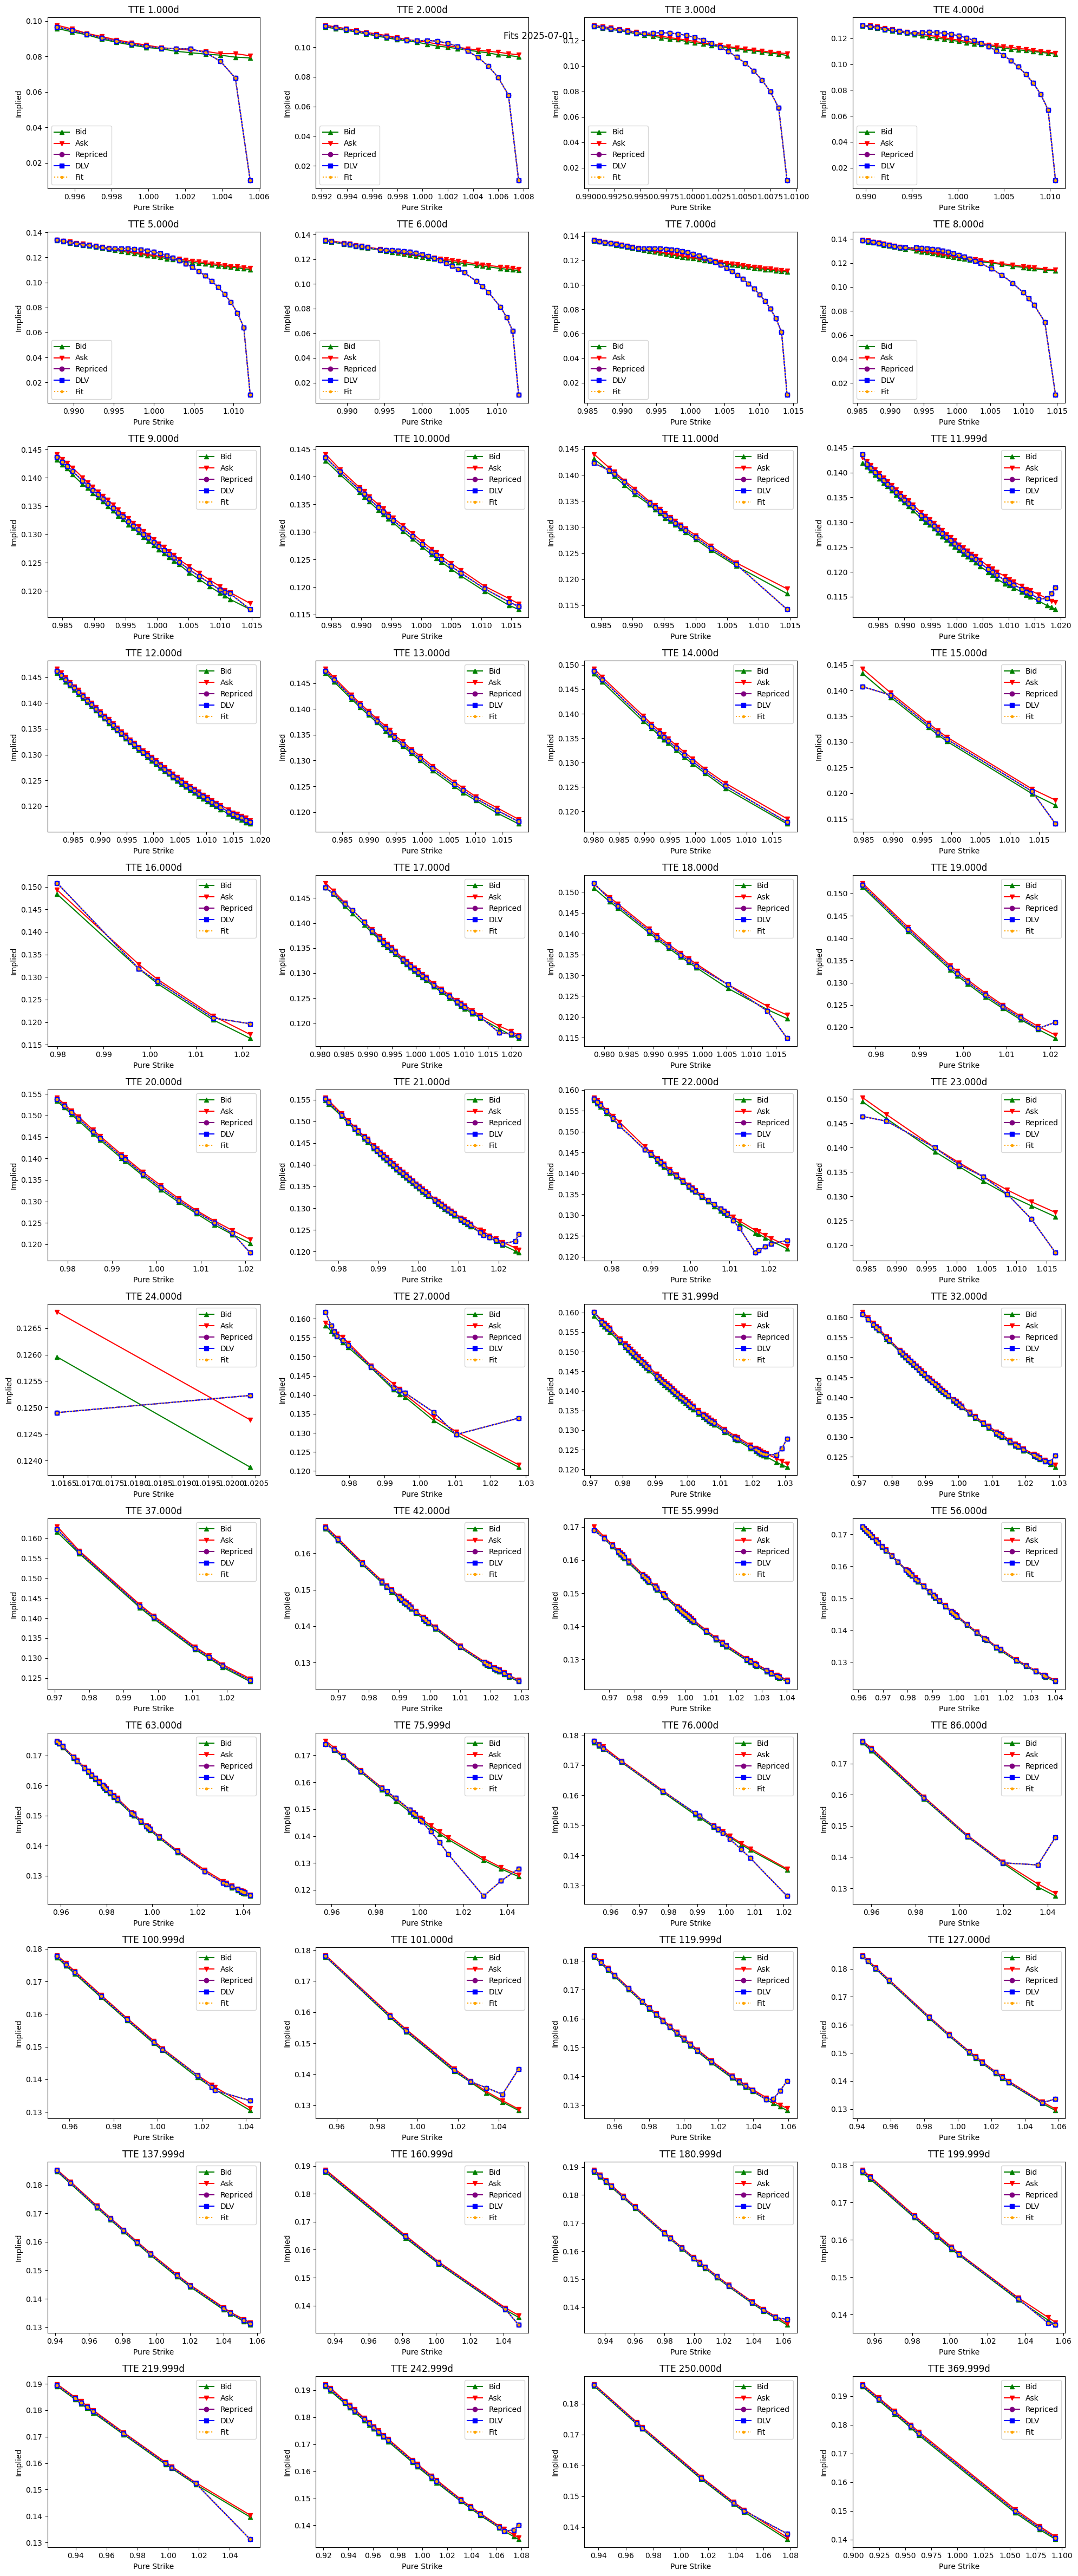

In [6]:
%aimport quantdata.sanos.utils
%aimport quantdata.sanos.open
%aimport quantdata.sanos.fitter

from cdxcore.bs import bs
from cdxcore.dynaplot import figure, store
from cdxcore.verbose import Context
from quantdata.biz_calendar import DAYS_PER_YEAR
from quantdata.sanos.open import OpenGeometryGenerator, OpenSanos
from quantdata.sanos.fitter import Eps, Fitter
import numpy as np

def fit(data):
    num_samples = len(data.dates)

    # configure open geometry generation
    # ----------------------------------

    geometry_generator = OpenGeometryGenerator(
                            dlv_min     = 0.01,
                            dlv_max     = 5.,
                            fwdvol_min  = 0.0,
                            vol_interp  = "lin_var",
                            min_dx      = 1e-5,
                            max_dx      = None,
                            lower_scale = 0.2,
                            upper_scale = 1.5,
                            max_dx_outer_fac = 1.
                        )

    eps         = Eps()

    def fit_sample( isample, store ):

        d          = data.dates[isample]
        is_valid   = data.is_valid[isample,:]
        strikes    = data.pure_strike[isample,is_valid]
        tte_y      = data.tte_y[isample,is_valid]
        bid_vol    = data.bid_vol[isample,is_valid]
        ask_vol    = data.ask_vol[isample,is_valid]
        bid        = data.bid_pure_price[isample,is_valid]
        ask        = data.ask_pure_price[isample,is_valid]

        # construct open geometry
        # -----------------------

        market_expiries   = np.unique(tte_y)
        market_strikes    = []
        for expiry in market_expiries:
            mask     = tte_y == expiry
            strikes_t = np.sort( strikes[mask] )
            market_strikes.append(strikes_t)

        geometry    = geometry_generator.create_geometry(
                            expiries     = market_expiries,
                            pure_strikes = market_strikes,
                            dtype        = np.float64,
                      )

        fitter      = Fitter( geometry = geometry, eps = eps, debug=True, max_error = None, mid_fit_weight = 0.1 )
        sanos       = OpenSanos( geometry = geometry, eps = eps, debug=True )

        # plot the geometry
        # -----------------

        with figure(f"Open Geometry {d}", col_size=5, row_size=4, columns=None ) as fig_strikes:
            axD, axA    = fig_strikes.add_subplots("Inner", "All")
            axD.set_xlabel("TTE")
            axA.set_xlabel("TTE")
            axD.set_ylabel("Pure Strike (log-scale)")
            axA.set_ylabel("Pure Strike (log-scale)")
            axA.set_yscale("log")
            axD.set_yscale("log")

            for xexpiry, xstrikes_t in zip(geometry.xexpiries, geometry.xstrikes):
                texp_all   = np.full(xstrikes_t.shape, xexpiry, dtype=np.float64)
                texp_inner = np.full(xstrikes_t[1:-1].shape, xexpiry, dtype=np.float64)
                axA.plot( texp_all, xstrikes_t, ".:" )
                axD.plot( texp_inner, xstrikes_t[1:-1], ".:" )

            fig_strikes.render()
            store = fig_strikes.store()

            def plot_strikes(store):
                utty, inv = np.unique(tte_y, return_inverse=True)

                min_strike = np.full(len(utty), np.inf, dtype=strikes.dtype)
                max_strike = np.full(len(utty), -np.inf, dtype=strikes.dtype)

                np.minimum.at(min_strike, inv, strikes)
                np.maximum.at(max_strike, inv, strikes)
            
                store.clear()
                store += axA.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")
                store += axD.fill_between(utty, min_strike, max_strike, alpha=0.3, color="blue")            
                store += axD.plot(utty, min_strike, ".-", color="blue")
                store += axD.plot(utty, max_strike, ".-", color="blue")
                store += axD.plot(tte_y, strikes, ".", color="blue")
                fig_strikes.render()

                return utty, min_strike, max_strike

            plot_strikes(store)


        # compute prices, dlvs
        # --------------------

        FWD_VOLS       = 0.0

        dlvsqs, fit_prices, densities = \
            fitter( fwd_vols     = FWD_VOLS,
                    opt_strikes  = strikes,
                    opt_bid      = bid,
                    opt_ask      = ask,
                    opt_tte      = tte_y,
                    opt_is_calls = None,
                    opt_mask     = None,
                    return_only_dlvsqs = False,
                    verbose      = Context.all ) 
        assert fit_prices.shape == strikes.shape, f"Expected fit_prices to have shape {strikes.shape}, got {fit_prices.shape}"
        fit_vols  = bs.implied(strikes, fit_prices, sqrtT = np.sqrt(tte_y) )

        re_prices = sanos.price(  fwd_vols     = FWD_VOLS,
                                  densities    = densities,
                                  opt_strikes  = strikes,
                                  opt_tte      = tte_y
                               )
        re_vols  = bs.implied(strikes, re_prices, sqrtT = np.sqrt(tte_y) )

        test_dens_from_dlv  = sanos.densities( dlvsqs )
        dlv_prices = sanos.price( fwd_vols     = FWD_VOLS,
                                  densities    = test_dens_from_dlv,
                                  opt_strikes  = strikes,
                                  opt_tte      = tte_y
                               )
        dlv_vols  = bs.implied(strikes, dlv_prices, sqrtT = np.sqrt(tte_y) )

        # DLVs, manual
        # ------------

        with figure(f"Fits {d}", col_size=5, row_size=4, columns=4 ) as fig_fits:

            uttys = np.unique(tte_y)

            for utty in uttys:
                mask = tte_y == utty
                ax = fig_fits.add_subplot(f"TTE {utty*DAYS_PER_YEAR:.3f}d")
                ax.set_xlabel("Pure Strike")
                ax.set_ylabel("Implied")

                istrike = strikes[mask]
                ixs     = np.argsort(istrike)

                ax.plot(istrike[ixs], bid_vol[mask][ixs], "^-", color="green", label="Bid")
                ax.plot(istrike[ixs], ask_vol[mask][ixs], "v-", color="red", label="Ask")
                ax.plot(istrike[ixs], re_vols[mask][ixs], "o-", color="purple", label="Repriced")
                ax.plot(istrike[ixs], dlv_vols[mask][ixs], "s-", color="blue", label="DLV")
                ax.plot(istrike[ixs], fit_vols[mask][ixs], ".:", color="orange", label="Fit")
                ax.legend()

    for isample in range(num_samples-1,num_samples-200,-20):
        fit_sample(isample, store)
        break

fit(data)
